# 04 · Closed-system integrators (Sec. III, Fig. 6)

Driven Kerr oscillator, Eq. (32):
$H(t)=\omega_0 a^\dagger a+\tfrac K2 a^{\dagger2}a^2+f(t)(a^2+a^{\dagger2})$, with $R=8$, $\omega_0=1$, $K=1/25$, $\alpha_0=4$ and the two-frequency drive of Eq. (34).

* **Fig. 6a**: $\alpha(t)=\langle a\rangle$ from the full dynamics and from the semiclassical equation (33), plus $|\psi_n|$ at three times.
* **Fig. 6b**: final infidelity $E=1-|\langle\psi_{\rm th}|\psi\rangle|$ versus step $h$ for the integrators of Sec. III A.

Without the QTT solver, panel b compares the **time-stepping rules** on dense vectors (RK4, Crank–Nicolson with 2nd-order Taylor propagators, an exponential with $H$ frozen at the start of the step — the time-dependence error that plain TDVP inherits — and the Magnus-4 exponential). With `qttlind`, the same panel runs the four QTT methods, including TDVP on the QTT manifold.

The paper does not give $t_f$ or the inset times; we use $t_f=5$ for panel b and $t\in\{0,10,20\}$ for the insets.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


In [2]:
R = 8; N = 2**R
H0, H1 = driven_kerr(R)
a = dr.destroy(N)
psi0 = dr.coherent(N, KERR["alpha0"])
T = 30.0
t_out = np.linspace(0, T, 301)
with timer("reference (Magnus-4, h=2.5e-3)"):
    ts, states = magnus4_evolve(psi0, H0, H1, kerr_drive, T, 2.5e-3, t_out)
alpha_t = np.array([np.vdot(s, a @ s) for s in states])

from scipy.integrate import solve_ivp
def semiclassical(t, y):
    al = y[0] + 1j * y[1]
    d = -1j * (KERR["omega0"] * al + 2 * kerr_drive(t) * np.conj(al) + KERR["K"] * abs(al)**2 * al)
    return [d.real, d.imag]
sc = solve_ivp(semiclassical, (0, T), [KERR["alpha0"], 0.0], t_eval=t_out, rtol=1e-10, atol=1e-12)

[reference (Magnus-4, h=2.5e-3)] 12.21 s


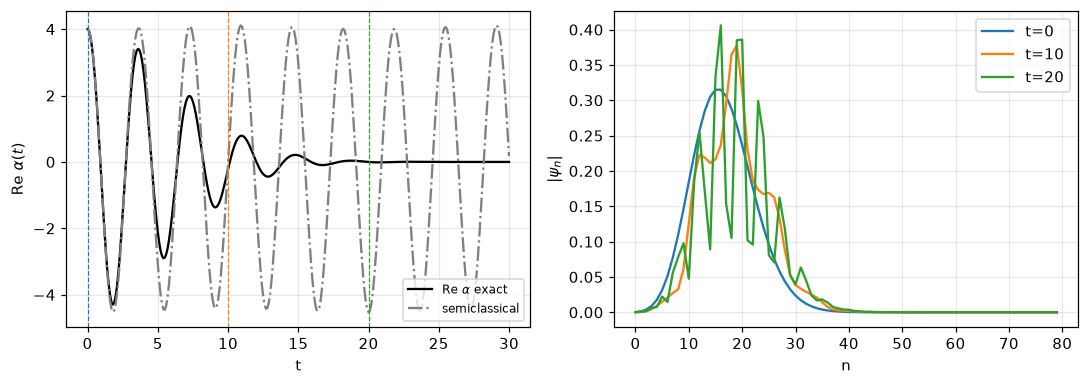

In [3]:
fig = plt.figure(figsize=(10, 3.6))
ax = fig.add_subplot(1, 2, 1)
ax.plot(ts, alpha_t.real, "k", label=r"Re $\alpha$ exact")
ax.plot(sc.t, sc.y[0], color="0.5", ls="-.", label="semiclassical")
for tc, col in zip([0, 10, 20], ["C0", "C1", "C2"]):
    ax.axvline(tc, color=col, ls="--", lw=0.8)
ax.set(xlabel="t", ylabel=r"Re $\alpha(t)$"); ax.legend(fontsize=8)
ax2 = fig.add_subplot(1, 2, 2)
for tc, col in zip([0, 10, 20], ["C0", "C1", "C2"]):
    k = int(np.argmin(abs(ts - tc)))
    ax2.plot(np.abs(states[k][:80]), color=col, label=f"t={tc}")
ax2.set(xlabel="n", ylabel=r"$|\psi_n|$"); ax2.legend()
plt.tight_layout(); savefig(fig, "fig06a_kerr_alpha.png"); plt.show()

## Fig. 6b — error versus time step

[reference (DOP853, rtol 1e-12)] 1.47 s


[RK4] 9.91 s


[Crank-Nicolson] 21.94 s


[frozen-H exponential] 27.55 s


[Magnus-4 exponential] 30.30 s


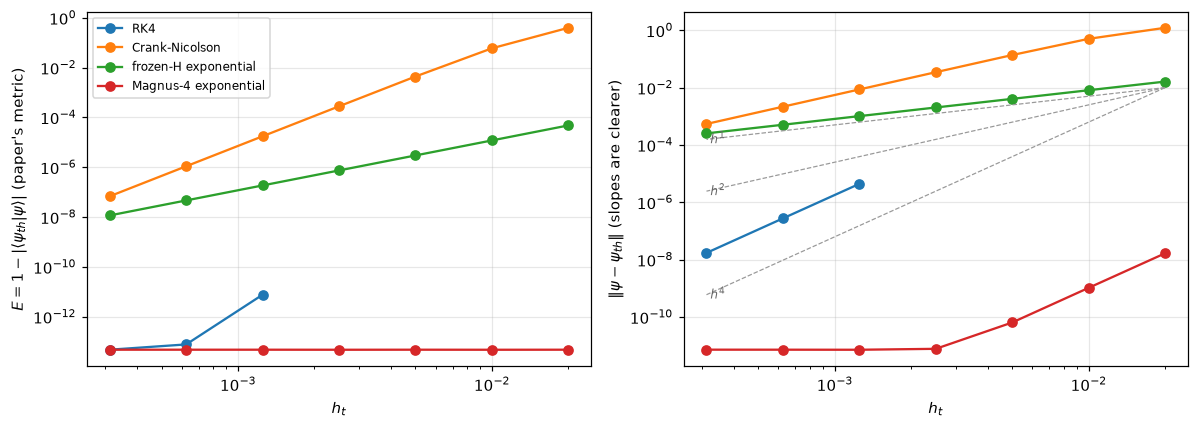

Magnus-4 flattens at ~1e-11: that is the precision of the DOP853 reference, not of the method.
Missing points = diverged (explicit RK4 is unstable once h * ||H|| exceeds ~2.8; here ||H|| ~ 1550 )


In [4]:
import scipy.sparse as sp
from scipy.sparse.linalg import expm_multiply, splu
Id = sp.identity(N, dtype=complex, format="csc")
Hf = lambda t: H0 + kerr_drive(t) * H1
tf = 5.0
# independent reference: adaptive 8th-order Runge-Kutta at tight tolerance
from scipy.integrate import solve_ivp
with timer("reference (DOP853, rtol 1e-12)"):
    sol = solve_ivp(lambda t, y: -1j * (Hf(t) @ y), (0, tf), psi0, method="DOP853", rtol=1e-12, atol=1e-14)
ref = sol.y[:, -1]

def run(method, h):
    psi = psi0.copy(); n = int(round(tf / h))
    for k in range(n):
        t = k * h
        if method == "RK4":
            k1 = -1j * (Hf(t) @ psi); k2 = -1j * (Hf(t + h/2) @ (psi + h/2 * k1))
            k3 = -1j * (Hf(t + h/2) @ (psi + h/2 * k2)); k4 = -1j * (Hf(t + h) @ (psi + h * k3))
            psi = psi + h/6 * (k1 + 2*k2 + 2*k3 + k4)
        elif method == "Crank-Nicolson":
            A, B = Hf(t + h), Hf(t)
            lhs = (Id + 0.5j*h*A - h*h/8 * (A @ A)).tocsc()
            rhs = psi - 0.5j*h*(B @ psi) - h*h/8 * (B @ (B @ psi))
            psi = splu(lhs).solve(rhs)
        elif method == "frozen-H exponential":
            psi = expm_multiply(-1j * h * Hf(t), psi)
        if not np.all(np.isfinite(psi)) or np.linalg.norm(psi) > 1e6:
            return np.nan, np.nan
    if method == "Magnus-4 exponential":
        psi = magnus4_evolve(psi0, H0, H1, kerr_drive, tf, h)[1][-1]
    return np.linalg.norm(psi - ref), 1 - abs(np.vdot(ref, psi)) / np.linalg.norm(psi)

hs = [2e-2, 1e-2, 5e-3, 2.5e-3, 1.25e-3, 6.25e-4, 3.125e-4]
errs = {}
for m in ["RK4", "Crank-Nicolson", "frozen-H exponential", "Magnus-4 exponential"]:
    with timer(m):
        errs[m] = [run(m, h) for h in hs]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
hh = np.array(hs)
for m, e in errs.items():
    e = np.array(e, dtype=float)
    axs[0].loglog(hs, np.clip(e[:, 1], 1e-16, None), "o-", label=m)
    axs[1].loglog(hs, np.clip(e[:, 0], 1e-16, None), "o-", label=m)
for p in (1, 2, 4):
    axs[1].loglog(hh, 1e-2 * (hh / hh[0])**p, color="0.6", ls="--", lw=0.8)
    axs[1].text(hh[-1], 1e-2 * (hh[-1] / hh[0])**p, f" $h^{p}$", color="0.4", fontsize=8, va="center")
axs[0].set(xlabel=r"$h_t$", ylabel=r"$E=1-|\langle\psi_{th}|\psi\rangle|$ (paper's metric)"); axs[0].legend(fontsize=8)
axs[1].set(xlabel=r"$h_t$", ylabel=r"$\|\psi-\psi_{th}\|$ (slopes are clearer)")
plt.tight_layout()
savefig(fig, "fig06b_integrator_errors.png"); plt.show()
print("Magnus-4 flattens at ~1e-11: that is the precision of the DOP853 reference, not of the method.")
print("Missing points = diverged (explicit RK4 is unstable once h * ||H|| exceeds ~2.8; here ||H|| ~", round(abs(H0.diagonal()).max()), ")")

src/qttlind/core/conventions.py:140: RuntimeWarning: overflow encountered in multiply
  w = s * s
src/qttlind/core/conventions.py:150: RuntimeWarning: invalid value encountered in scalar divide
  return keep, float(w[keep:].sum() / total)
.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2782: RuntimeWarning: overflow encountered in dot
  sqnorm = x_real.dot(x_real) + x_imag.dot(x_imag)


src/qttlind/core/linalg.py:134: RuntimeWarning: overflow encountered in matmul
  res = (am.reshape(-1, k) @ bm.reshape(k, -1)).reshape(out_shape)
src/qttlind/core/linalg.py:134: RuntimeWarning: invalid value encountered in matmul
  res = (am.reshape(-1, k) @ bm.reshape(k, -1)).reshape(out_shape)


[QTT rk4] 112.58 s


[QTT crank_nicolson] 153.54 s


[QTT tdvp] 96.44 s


[QTT magnus_tdvp] 132.54 s


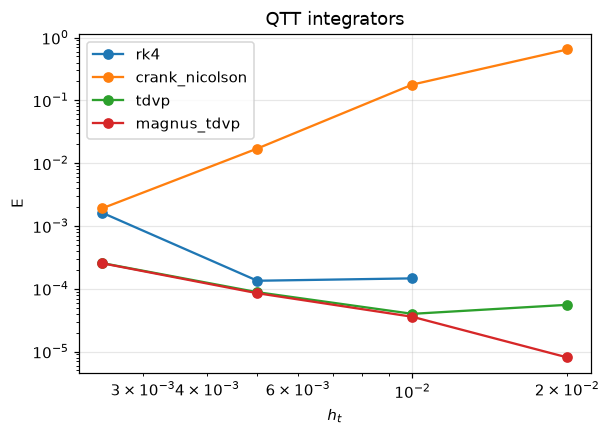

In [5]:
if HAVE_QTTLIND:
    # The same panel with the QTT integrators (quick mode: the four largest steps)
    sysq = ql.System(); m = sysq.add_mode("osc", bits=R)
    H = KERR["omega0"] * m.n() + KERR["K"] / 2 * m.dag()**2 * m**2 + ql.coeff(kerr_drive) * (m**2 + m.dag()**2)
    p0 = sysq.product_state(osc=ql.states.coherent(KERR["alpha0"]))
    hs_q = hs if PAPER_SIZE else hs[:4]
    fig, ax = plt.subplots(figsize=(6, 4))
    for meth in ["rk4", "crank_nicolson", "tdvp", "magnus_tdvp"]:
        e = []
        with timer(f"QTT {meth}"):
            for h in hs_q:
                try:
                    psi = ql.evolve_closed(p0, H, t_final=tf, dt=h, method=meth, tol=1e-8).final_state.to_dense()
                    e.append(1 - abs(np.vdot(ref, psi)) / np.linalg.norm(psi) if np.all(np.isfinite(psi)) else np.nan)
                except (ValueError, np.linalg.LinAlgError, ql.errors.ConvergenceError):
                    e.append(np.nan)   # explicit RK4 beyond its stability limit diverges, as in the dense panel
        ax.loglog(hs_q, np.clip(e, 1e-16, None), "o-", label=meth)
    ax.set(xlabel=r"$h_t$", ylabel="E", title="QTT integrators"); ax.legend(); plt.show()